# Practical 1 — Fibonacci Numbers: Recursive and Iterative Algorithms

**Subject:** Design and Analysis of Algorithms (410241)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Write a non-recursive (iterative) and a recursive program to calculate the
$n^{th}$ Fibonacci number, and analyse the time and space complexity of both
approaches.

## 2. Problem statement

The Fibonacci sequence is defined by the recurrence

$$F_0 = 0,\qquad F_1 = 1,\qquad F_n = F_{n-1} + F_{n-2}\ \ (n \ge 2).$$

Implement the following three variants and compare them:

1. **Naive recursion** — a direct translation of the recurrence.
2. **Iterative (bottom-up)** — compute the sequence with a loop.
3. **Memoisation (top-down DP)** — recursion with a cache (added for comparison).

## 3. Objectives

- Understand how a recurrence relation is converted into a recursive function.
- Understand the role of the call stack in recursion.
- Measure running time empirically and relate it to asymptotic complexity.
- Compare recursion, iteration and dynamic programming.

## 4. Theory

### 4.1 Recursive formulation

```text
FIB-REC(n)
    if n < 2
        return n
    return FIB-REC(n-1) + FIB-REC(n-2)
```

The recursion tree for `FIB-REC(5)` is:

```text
                    fib(5)
                 /          \
             fib(4)         fib(3)
            /     \        /     \
        fib(3)   fib(2)  fib(2)  fib(1)
        /   \     /  \    /  \
    fib(2) fib(1) ...  ... ... ...
```

The same sub-problem (for example `fib(2)`) is solved many times. The number
of calls grows approximately as $\phi^n$, where $\phi = (1+\sqrt5)/2 \approx
1.618$ is the golden ratio. Therefore the running time is **exponential**,
$O(2^n)$ (more precisely $\Theta(\phi^n)$).

The recursion depth is $n$, so the call stack uses **$O(n)$ space**.

### 4.2 Iterative formulation

Only the previous two values are needed:

```text
FIB-ITER(n)
    if n < 2: return n
    a = 0; b = 1
    for i = 2 to n
        c = a + b
        a = b
        b = c
    return b
```

This performs $n-1$ additions, so the time complexity is **$O(n)$** and the
extra space is **$O(1)$**.

### 4.3 Memoisation

A cache stores each $F_i$ the first time it is computed. Every state is
computed once, so the time becomes **$O(n)$** and the space becomes **$O(n)$**
for the cache plus $O(n)$ for the call stack.

### 4.4 Summary

| Variant | Time | Extra space | Recomputes sub-problems? |
|---|---|---|---|
| Naive recursion | $O(2^n)$ | $O(n)$ stack | Yes |
| Iterative | $O(n)$ | $O(1)$ | No |
| Memoised recursion | $O(n)$ | $O(n)$ | No |

> **Note on Python integers.** Python uses arbitrary-precision integers, so
> adding two large Fibonacci numbers is not a constant-time operation. The
> $O(n)$ bound is the standard unit-cost RAM model; for very large $n$ the
> bit complexity also grows because $F_n$ has $\Theta(n)$ bits.

In [1]:
from functools import lru_cache
from time import perf_counter
import sys

import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.6g}")

In [2]:
def fib_recursive(n: int, calls: list | None = None) -> int:
    """Return F(n) using the direct recursive definition.

    ``calls`` is an optional one-element list used as a counter so that the
    number of function calls can be measured without a global variable.
    """
    if n < 0:
        raise ValueError("n must be a non-negative integer")
    if calls is not None:
        calls[0] += 1
    if n < 2:
        return n
    return fib_recursive(n - 1, calls) + fib_recursive(n - 2, calls)


def fib_iterative(n: int) -> int:
    """Return F(n) using O(n) time and O(1) extra space."""
    if n < 0:
        raise ValueError("n must be a non-negative integer")
    if n < 2:
        return n
    previous, current = 0, 1
    for _ in range(2, n + 1):
        previous, current = current, previous + current
    return current


@lru_cache(maxsize=None)
def fib_memoised(n: int) -> int:
    """Return F(n) using top-down dynamic programming (memoisation)."""
    if n < 0:
        raise ValueError("n must be a non-negative integer")
    if n < 2:
        return n
    return fib_memoised(n - 1) + fib_memoised(n - 2)

In [3]:
# Test case 1: the first 15 Fibonacci numbers should match in all variants.
first_fifteen = [fib_iterative(n) for n in range(15)]
print("First 15 Fibonacci numbers:")
print(first_fifteen)

assert all(
    fib_recursive(n) == fib_memoised(n) == fib_iterative(n) == first_fifteen[n]
    for n in range(15)
)
print("\nAll three implementations agree for n = 0 ... 14  ✓")

First 15 Fibonacci numbers:
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]

All three implementations agree for n = 0 ... 14  ✓


In [4]:
# Test case 2: boundary and invalid inputs.
print("F(0)  =", fib_iterative(0))
print("F(1)  =", fib_iterative(1))
print("F(10) =", fib_iterative(10))
print("F(50) =", fib_iterative(50))

for bad_value in (-1, -10):
    try:
        fib_iterative(bad_value)
    except ValueError as error:
        print(f"ValueError for n={bad_value}: {error}")

F(0)  = 0
F(1)  = 1
F(10) = 55
F(50) = 12586269025
ValueError for n=-1: n must be a non-negative integer
ValueError for n=-10: n must be a non-negative integer


In [5]:
# Count how many recursive calls are made for selected values of n.
call_counts = []
for n in range(0, 21):
    counter = [0]
    value = fib_recursive(n, counter)
    call_counts.append({"n": n, "F(n)": value, "recursive calls": counter[0]})

call_table = pd.DataFrame(call_counts)
call_table.head(11)

,n,F(n),recursive calls
0,0,0,1
1,1,1,1
2,2,1,3
3,3,2,5
4,4,3,9
5,5,5,15
6,6,8,25
7,7,13,41
8,8,21,67
9,9,34,109


The number of calls roughly doubles when $n$ increases by one, which is the
signature of exponential growth. For `n = 20` the recursive version already
makes more than 20,000 calls for a result that the loop computes in 20 steps.

In [6]:
# Benchmark the recursive version. The values are intentionally kept small:
# the runtime grows exponentially and n = 35 would already take several seconds.
recursive_sizes = [5, 10, 15, 20, 22, 24, 26, 28, 30, 32]
recursive_times = []

for n in recursive_sizes:
    start = perf_counter()
    fib_recursive(n)
    elapsed = perf_counter() - start
    recursive_times.append(elapsed)

recursive_results = pd.DataFrame(
    {"n": recursive_sizes, "time (seconds)": recursive_times}
)
recursive_results

,n,time (seconds)
0,5,2.426e-06
1,10,1.2788e-05
2,15,0.000115385
3,20,0.00138368
4,22,0.00366711
5,24,0.010033
6,26,0.0281377
7,28,0.077856
8,30,0.199369
9,32,0.52512


In [7]:
# Benchmark the iterative version for much larger inputs.
iterative_sizes = [10, 100, 1_000, 5_000, 10_000, 50_000, 100_000]
iterative_times = []

for n in iterative_sizes:
    start = perf_counter()
    fib_iterative(n)
    elapsed = perf_counter() - start
    iterative_times.append(elapsed)

iterative_results = pd.DataFrame(
    {"n": iterative_sizes, "time (seconds)": iterative_times}
)
iterative_results

,n,time (seconds)
0,10,2.275e-06
1,100,6.174e-06
2,1000,7.1879e-05
3,5000,0.000524037
4,10000,0.00147488
5,50000,0.0272385
6,100000,0.101217


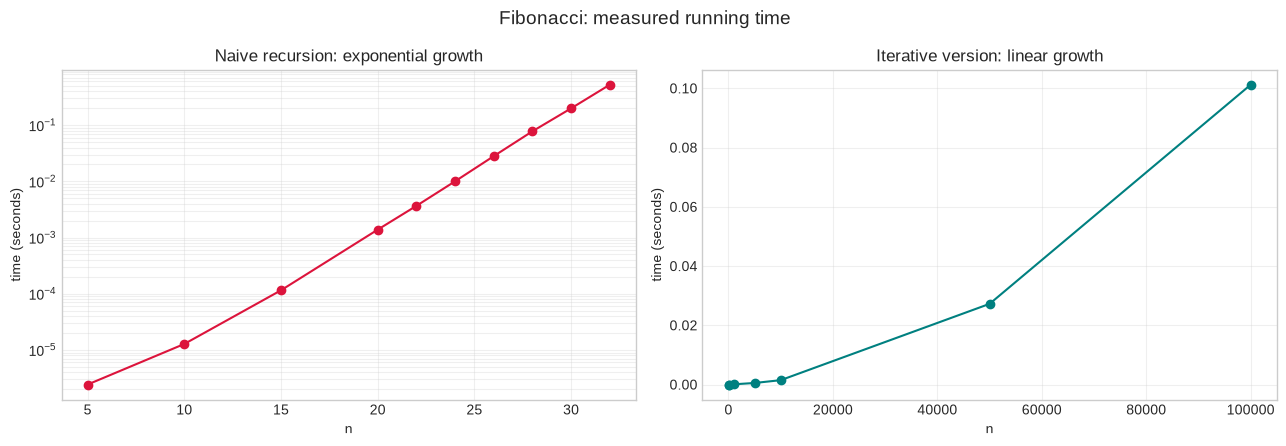

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    recursive_results["n"],
    recursive_results["time (seconds)"],
    "o-",
    color="crimson",
)
axes[0].set_title("Naive recursion: exponential growth")
axes[0].set_xlabel("n")
axes[0].set_ylabel("time (seconds)")
axes[0].set_yscale("log")
axes[0].grid(True, which="both", alpha=0.3)

axes[1].plot(
    iterative_results["n"],
    iterative_results["time (seconds)"],
    "o-",
    color="teal",
)
axes[1].set_title("Iterative version: linear growth")
axes[1].set_xlabel("n")
axes[1].set_ylabel("time (seconds)")
axes[1].grid(True, alpha=0.3)

fig.suptitle("Fibonacci: measured running time", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
# A direct comparison at n = 30: recursion vs iteration vs memoisation.
n = 30
start = perf_counter(); value_recursive = fib_recursive(n); time_recursive = perf_counter() - start
start = perf_counter(); value_iterative = fib_iterative(n); time_iterative = perf_counter() - start
start = perf_counter(); value_memoised = fib_memoised(n);  time_memoised = perf_counter() - start

comparison = pd.DataFrame(
    [
        {"variant": "Naive recursion", "F(30)": value_recursive,
         "time (seconds)": time_recursive},
        {"variant": "Iterative", "F(30)": value_iterative,
         "time (seconds)": time_iterative},
        {"variant": "Memoised", "F(30)": value_memoised,
         "time (seconds)": time_memoised},
    ]
)
comparison

,variant,F(30),time (seconds)
0,Naive recursion,832040,0.21134
1,Iterative,832040,7.2801e-05
2,Memoised,832040,8.2672e-05


In [10]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
# This final cell converts the raw numbers above into a guided report. Every
# number below is read from the variables that were computed in this notebook,
# so the explanation stays correct if the notebook is executed again.
print("DETAILED OUTPUT EXPLANATION - DAA Practical 1 (Fibonacci)")
print("=" * 78)
print(
    "The experiment compares three ways to compute F(n): naive recursion,\n"
    "bottom-up iteration and top-down memoisation. The key question is not\n"
    "only whether they return the same value, but how much work each one does."
)

print("\n1. CORRECTNESS OF THE THREE IMPLEMENTATIONS")
print("-" * 78)
print("First 15 Fibonacci numbers:", first_fifteen)
print("F(0), F(1), F(10), F(50):",
      fib_iterative(0), fib_iterative(1), fib_iterative(10), fib_iterative(50))
print(
    "All three variants agree for n = 0 ... 14:",
    all(fib_recursive(i) == fib_memoised(i) == fib_iterative(i) for i in range(15)),
)
print("Interpretation: the three code paths implement the same recurrence,")
print("so correctness checks must pass before any timing comparison is valid.")

print("\n2. RECURSIVE CALL COUNT (THE EXPONENTIAL WORK)")
print("-" * 78)
calls_20 = int(call_table.loc[call_table["n"] == 20, "recursive calls"].iloc[0])
calls_19 = int(call_table.loc[call_table["n"] == 19, "recursive calls"].iloc[0])
growth_factor = calls_20 / calls_19
print(f"Recursive calls for n=19 : {calls_19:,}")
print(f"Recursive calls for n=20 : {calls_20:,}")
print(f"Growth factor from n=19 to n=20: {growth_factor:.3f}x")
print("The call count multiplies by roughly the golden ratio (about 1.618)")
print("when n increases by one. This is why naive recursion is exponential:")
print("the same sub-problems (for example F(2)) are solved again and again.")

print("\n3. MEASURED RUNNING TIME")
print("-" * 78)
recursive_max_n = int(recursive_results["n"].max())
recursive_max_time = float(
    recursive_results.loc[recursive_results["n"] == recursive_max_n, "time (seconds)"].iloc[0]
)
iterative_max_n = int(iterative_results["n"].max())
iterative_max_time = float(
    iterative_results.loc[iterative_results["n"] == iterative_max_n, "time (seconds)"].iloc[0]
)
print(f"Naive recursion at n={recursive_max_n}: {recursive_max_time:.6f} s")
print(f"Iterative loop  at n={iterative_max_n:,}: {iterative_max_time:.6f} s")
print(
    "The iterative version handles an input about "
    f"{iterative_max_n / recursive_max_n:,.0f} times larger while still being "
    "faster."
)
print("The recursive benchmark stops at small n because its runtime explodes;")
print("the iterative benchmark can continue to n=100,000 without a stack limit.")

print("\n4. DIRECT COMPARISON AT n = 30")
print("-" * 78)
for _, row in comparison.iterrows():
    print(f"{row['variant']:18s}: F(30) = {row['F(30)']:,}, time = {row['time (seconds)']:.6f} s")
recursive_30 = float(
    comparison.loc[comparison["variant"] == "Naive recursion", "time (seconds)"].iloc[0]
)
iterative_30 = float(
    comparison.loc[comparison["variant"] == "Iterative", "time (seconds)"].iloc[0]
)
memoised_30 = float(
    comparison.loc[comparison["variant"] == "Memoised", "time (seconds)"].iloc[0]
)
print(f"All three F(30) values are equal: {comparison['F(30)'].nunique() == 1}")
print(f"Iterative is {recursive_30 / max(iterative_30, 1e-15):,.0f}x faster than naive recursion.")
print(f"Memoisation is {recursive_30 / max(memoised_30, 1e-15):,.0f}x faster than naive recursion.")
print("Memoisation removes repeated work but keeps the recursive call overhead,")
print("so the iterative constant factor is usually the smallest.")

print("\n5. COMPLEXITY TAKEAWAY")
print("-" * 78)
print("Naive recursion : time O(2^n) / Theta(phi^n), stack space O(n)")
print("Iterative       : time O(n), extra space O(1)")
print("Memoised        : time O(n), cache + stack space O(n)")
print("Use the iterative version in production. Use recursion only when the")
print("recursive structure is clearer and memoisation removes the repeated work.")

DETAILED OUTPUT EXPLANATION - DAA Practical 1 (Fibonacci)
The experiment compares three ways to compute F(n): naive recursion,
bottom-up iteration and top-down memoisation. The key question is not
only whether they return the same value, but how much work each one does.

1. CORRECTNESS OF THE THREE IMPLEMENTATIONS
------------------------------------------------------------------------------
First 15 Fibonacci numbers: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]
F(0), F(1), F(10), F(50): 0 1 55 12586269025
All three variants agree for n = 0 ... 14: True
Interpretation: the three code paths implement the same recurrence,
so correctness checks must pass before any timing comparison is valid.

2. RECURSIVE CALL COUNT (THE EXPONENTIAL WORK)
------------------------------------------------------------------------------
Recursive calls for n=19 : 13,529
Recursive calls for n=20 : 21,891
Growth factor from n=19 to n=20: 1.618x
The call count multiplies by roughly the golden ratio

### Observations

1. The recursive implementation is a direct translation of the mathematical
   definition and is easy to read, but it recomputes the same values many
   times. Its runtime grows exponentially.
2. The iterative implementation performs one addition per term and uses only
   two variables. It is dramatically faster for large $n$.
3. Memoisation keeps the recursive structure but removes repeated work. It is
   a good compromise when the recursive formulation is more natural.
4. Recursion is limited by the Python call-stack limit. The iterative version
   has no such limit and can compute very large indices (subject only to time
   and memory).

### Complexity analysis

| Variant | Recurrence / loop | Time | Space |
|---|---|---|---|
| Recursive | $T(n)=T(n-1)+T(n-2)+O(1)$ | $O(2^n)$ | $O(n)$ call stack |
| Iterative | one loop of $n-1$ iterations | $O(n)$ | $O(1)$ |
| Memoised | each state once | $O(n)$ | $O(n)$ |

## 5. Conclusion

We implemented recursive, iterative and memoised Fibonacci algorithms and
verified that they produce the same sequence. The experiment clearly shows
the difference between exponential and linear growth: the recursive version
is elegant but impractical for large $n$, while the iterative version is
simple, fast and memory-efficient. Memoisation demonstrates how dynamic
programming removes overlapping sub-problems.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is the recurrence for Fibonacci numbers? | $F_n=F_{n-1}+F_{n-2}$, with $F_0=0,F_1=1$. |
| Why is naive recursion exponential? | It solves the same sub-problems repeatedly; the call tree has about $\phi^n$ nodes. |
| What is the space complexity of recursive Fibonacci? | $O(n)$ because the call stack can be $n$ levels deep. |
| How does memoisation improve it? | It caches each result, so each state is computed once: $O(n)$ time. |
| Which version would you use in production? | The iterative version: $O(n)$ time, $O(1)$ extra space, no stack limit. |
| What is the difference between recursion and iteration? | Recursion uses the call stack and a base case; iteration uses a loop and explicit state. |
| What is tail recursion? | A recursive call that is the last operation; some languages optimise it into a loop. Python does not. |